# Практическое занятие №3-4

**Дисциплина:** Алгоритмы машинного обучения для решения прикладных задач  
**Тема:** Парная линейная регрессия, полиномиальная регрессия.  
Гребневая регрессия, LASSO, Elastic Net.  



In [19]:
# Импорт библиотек

from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from IPython.display import Image

# Настройки отображения
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## Ирисы Фишера

Выборка взята отсюда:  
https://archive.ics.uci.edu/ml/datasets/iris


### Загрузка выборки

In [8]:
from ucimlrepo import fetch_ucirepo

# Загружаем датасет Ирисов
iris = fetch_ucirepo(id=53)

X = iris.data.features
y = iris.data.targets

dataset = pd.concat([X, y], axis=1)

dataset.columns = [
    'длина чашелистика',
    'ширина чашелистика',
    'длина лепестка',
    'ширина лепестка',
    'klacc'
]

# Выбираем случайно
dataset.sample(5, random_state=0)

,длина чашелистика,ширина чашелистика,длина лепестка,ширина лепестка,klacc
114,5.8,2.8,5.1,2.4,Iris-virginica
62,6.0,2.2,4.0,1.0,Iris-versicolor
33,5.5,4.2,1.4,0.2,Iris-setosa
107,7.3,2.9,6.3,1.8,Iris-virginica
7,5.0,3.4,1.5,0.2,Iris-setosa


### Начало работы с данными

1. Определить множество объектов:
   - размер выборки;
   - признаки, которыми описываются объекты.
2. Определить множество ответов.
3. Определить тип задачи машинного обучения.


In [9]:
# Размер выборки
print('Размер выборки составляет l={} объектов.'.format(len(dataset)))

# Признаки
print('Признаки:', list(dataset.columns[:-1]))

# Классы
print('Классы:', dataset['klacc'].unique())


Размер выборки составляет l=150 объектов.
Признаки: ['длина чашелистика', 'ширина чашелистика', 'длина лепестка', 'ширина лепестка']
Классы: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


### Анализ данных

Проектируем объекты на двумерные плоскости для упрощения анализа.


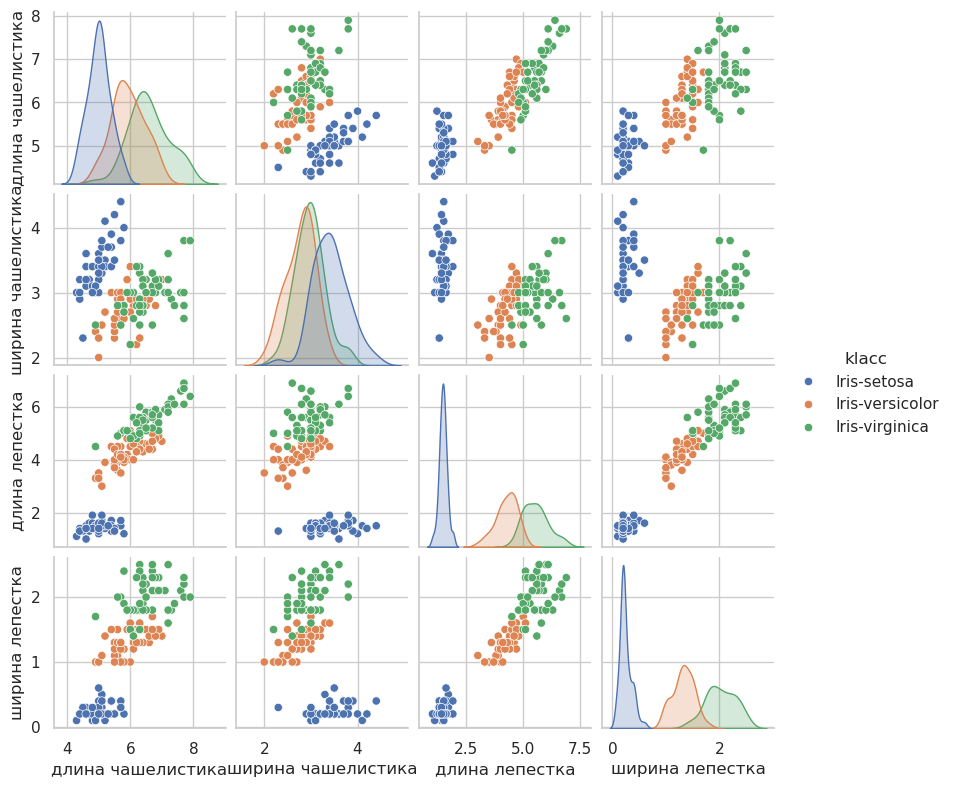

In [10]:
# Визуализация попарных зависимостей
# hue — цвет по классу
sns.pairplot(dataset, hue='klacc', height=2)
plt.show()


Из рисунка видно, что класс `Iris-setosa` легко отделяется от двух других.  
`Iris-versicolor` и `Iris-virginica` разделяются сложнее, но всё же можно провести прямую, которая их разделит.


## Построение модели

### Преобразование данных

Исходная задача — классификация на 3 класса.  
Для наглядности рассмотрим бинарную классификацию: удалим объекты класса `Iris-setosa`.


In [12]:
# Удаляем Iris-setosa
binary_dataset = dataset.drop(index=dataset.index[dataset['klacc'] == 'Iris-setosa']).copy()

# Кодируем классы числами: Iris-versicolor -> -1, Iris-virginica -> 1
binary_dataset.loc[binary_dataset['klacc'] == 'Iris-versicolor', 'klacc'] = -1
binary_dataset.loc[binary_dataset['klacc'] == 'Iris-virginica', 'klacc'] = 1

# Проверяем
binary_dataset['klacc'].value_counts()


klacc
-1    50
1     50
Name: count, dtype: int64

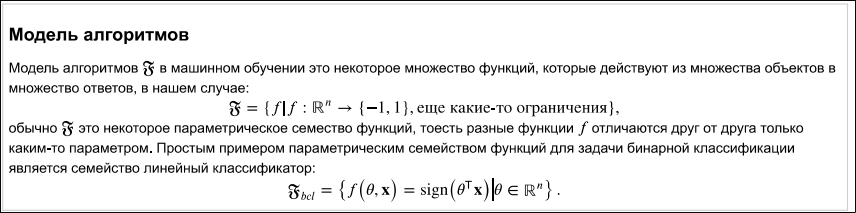
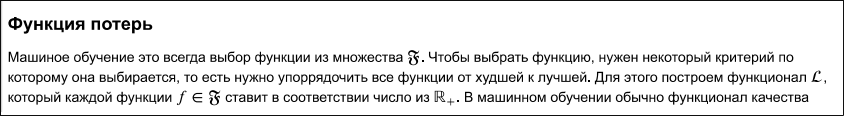
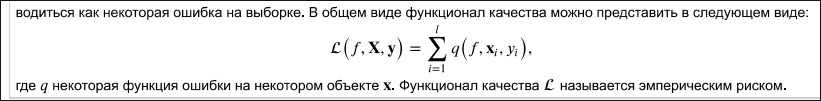
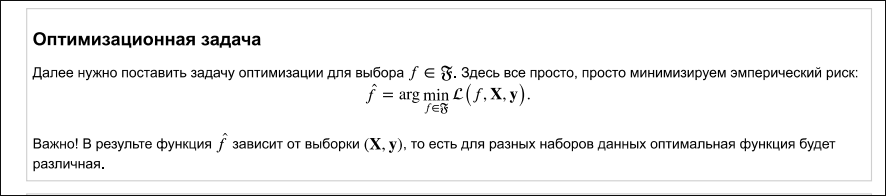
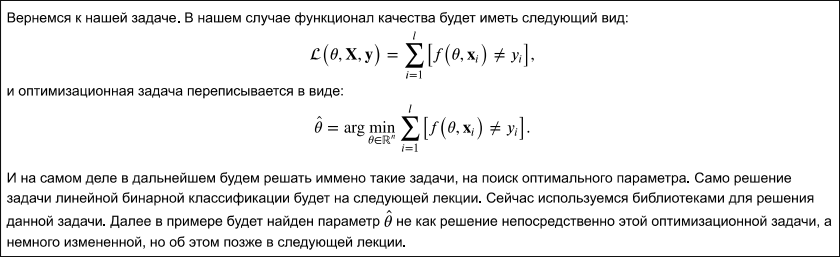

### Поиск оптимального вектора параметров

Переходим к матрице объектов X in R ^ (l * (n+1)) и вектору ответов y in {-1, 1} ^ l.  
Добавляем столбец единиц для свободного члена.


In [13]:
# Формируем матрицу признаков и вектор ответов
X = binary_dataset.drop(columns='klacc').values
y = binary_dataset['klacc'].values.reshape(-1)

# Добавляем столбец единиц ( bias / свободный член )
X = np.hstack([X, np.ones([len(X), 1])]).astype(np.float64)
y = y.astype(np.int64)

# Обучаем логистическую регрессию
model = LogisticRegression(random_state=0, max_iter=2000)
model.fit(X, y)

# Вектор оптимальных параметров
print('Коэффициенты модели:')
print(model.coef_)


Коэффициенты модели:
[[-3.94857799e-01 -5.12236925e-01  2.93150207e+00  2.41616121e+00
  -1.17463494e-03]]


## Практическая часть: классификация вина

Загрузите файл `winequality-red.csv` с помощью `pd.read_csv`.  
Последний столбец отвечает за качество вина.  
Будем считать, что **хорошее вино** — это качество **7 и выше**.  
Остальное вино — **некачественное**.

Нужно сделать классификацию вина по данному датасету.  
Два класса: `"Хорошее"` и `"Не качественное"`.  
Результатом будем считать уравнение гиперповерхности, отделяющее один класс от другого.


### Загрузка и подготовка данных

In [22]:
# Загружаем датасет red wine quality.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

try:
    wine = pd.read_csv(url, sep=';')
except Exception as e:
    print("Не удалось скачать по URL, пробую локальный файл winequality-red.csv")
    wine = pd.read_csv('winequality-red.csv', sep=';')

# Последний столбец quality. Хорошее вино — quality >= 7.
wine['good'] = (wine['quality'] >= 7).astype(int)

# Признаки и целевая переменная
X_wine = wine.drop(columns=['quality', 'good']).values
y_wine = wine['good'].values
feature_names = wine.drop(columns=['quality', 'good']).columns

print(wine.head())
print("Размер:", wine.shape)
print("Распределение классов:")
print(wine['good'].value_counts())


   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  good  
0      9.4        5     0  
1      9.8        5     0  
2 

### Обучение логистической регрессии и оценка качества

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Разделяем на train/test, чтобы оценить качество.
X_train, X_test, y_train, y_test = train_test_split(
    X_wine, y_wine,
    test_size=0.25,
    random_state=0,
    stratify=y_wine
)

# Логистическая регрессия.
# class_weight='balanced' помогает при дисбалансе классов.
clf = LogisticRegression(max_iter=5000, class_weight='balanced', random_state=0)
clf.fit(X_train, y_train)

# Предсказания и метрики.
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Не качественное', 'Хорошее']
))


Accuracy: 0.7625

Confusion matrix:
[[270  76]
 [ 19  35]]

Classification report:
                 precision    recall  f1-score   support

Не качественное       0.93      0.78      0.85       346
        Хорошее       0.32      0.65      0.42        54

       accuracy                           0.76       400
      macro avg       0.62      0.71      0.64       400
   weighted avg       0.85      0.76      0.79       400



### Уравнение гиперплоскости

Обучаем финальную модель на всех данных и выписываем уравнение:

z = b + w_1 x_1 + w_2 x_2 + ... + w_n x_n

Класс `"Хорошее"` — если \(z > 0\), иначе `"Не качественное"`.  
Разделяющая гиперповерхность: \(z = 0\).


In [21]:
# Обучаем финальную модель на всех данных, чтобы выписать уравнение гиперплоскости.
final_clf = LogisticRegression(max_iter=5000, class_weight='balanced', random_state=0)
final_clf.fit(X_wine, y_wine)

coef = final_clf.coef_[0]
intercept = final_clf.intercept_[0]

# Собираем уравнение z = b + w1*x1 + ... + wn*xn
terms = [f"{intercept:.6f}"]
for name, c in zip(feature_names, coef):
    terms.append(f"{c:+.6f}*{name}")

equation = " ".join(terms).replace("+ -", "- ")

print("Уравнение гиперплоскости, отделяющей 'Хорошее' от 'Не качественное':")
print(f"z = {equation}")

Уравнение гиперплоскости, отделяющей 'Хорошее' от 'Не качественное':
z = -12.046953 +0.141406*fixed acidity -3.028906*volatile acidity -0.220503*citric acid +0.134567*residual sugar -1.788957*chlorides +0.011884*free sulfur dioxide -0.013242*total sulfur dioxide -0.019543*density -0.703905*pH +2.659862*sulphates +1.190916*alcohol
